In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import time

In [2]:
roll_number = "M26CSE017"

In [3]:
seed = int("".join([ch for ch in roll_number if ch.isdigit()]))

In [4]:
seed

26017

In [5]:
rng = np.random.default_rng(seed)
print("Using seed:",seed)

Using seed: 26017


In [6]:
faces = fetch_olivetti_faces()
x = faces.data
y = faces.target

In [7]:
train_idx,val_idx,test_idx = [],[],[]
for person_id in range(40):
    person_indices = np.where(y == person_id)[0]
    shuffled=rng.permutation(person_indices)
    train_idx.extend(shuffled[:6])
    val_idx.extend(shuffled[6:8])
    test_idx.extend(shuffled[8:10])
train_idx = np.array(train_idx) 
val_idx = np.array(val_idx)
test_idx = np.array(test_idx)

x_train,y_train = x[train_idx],y[train_idx]
x_val,y_val = x[val_idx],y[val_idx]
x_test,y_test = x[test_idx],y[test_idx]

In [8]:
temp_images = x_test.copy().reshape(-1,64,64)
temp_images[:,24:40,24:40] = 0.0
x_test_masked = temp_images.reshape(-1,4096)
np.savez(
    "olivetti_splits.npz",
    train_idx = train_idx,val_idx = val_idx,test_idx =test_idx,
    x_train = x_train, y_train = y_train,
    x_val = x_val, y_val = y_val,
    x_test = x_test , y_test = y_test,
    x_test_masked = x_test_masked
)

In [9]:
# Q1(a)
max_depths = [2, 4, 8, 16, None]
min_samples_leafs = [1, 2, 4]

data = np.load("olivetti_splits.npz")
x_train, y_train = data["x_train"], data["y_train"]
x_val, y_val = data["x_val"], data["y_val"]
x_test, y_test = data["x_test"], data["y_test"]
all_results = []
best_val_acc = -1
best_params = {}
best_tree = None

for md in max_depths:
    for msl in min_samples_leafs:
        dt = DecisionTreeClassifier(
            max_depth=md,
            min_samples_leaf=msl,
            random_state=seed
        )
        dt.fit(x_train, y_train)
        train_acc = accuracy_score(y_train, dt.predict(x_train))
        val_acc = accuracy_score(y_val, dt.predict(x_val))
        test_acc = accuracy_score(y_test, dt.predict(x_test))
        n_nodes = dt.tree_.node_count
        children_left = dt.tree_.children_left
        children_right = dt.tree_.children_right
        node_samples = dt.tree_.n_node_samples
        leaf_samples = []
        for i in range(n_nodes):
            if children_left[i] == children_right[i]:
                leaf_samples.append(node_samples[i])

        n_leaves = len(leaf_samples)
        mean_samples = np.mean(leaf_samples) if n_leaves > 0 else 0
        fraction_single = (
            np.sum(np.array(leaf_samples) == 1) / n_leaves
            if n_leaves > 0 else 0
        )
        all_results.append({
            "Max Depth": str(md),
            "Min Samples Leaf": msl,
            "Train Acc": f"{train_acc * 100:.2f}%",
            "Val Acc": f"{val_acc * 100:.2f}%",
            "Test Acc": f"{test_acc * 100:.2f}%",
            "Number of Leaves": n_leaves,
            "Mean Samples/Leaf": f"{mean_samples:.2f}",
            "Fraction Single-Sample Leaves":
                f"{fraction_single * 100:.2f}%"
        })
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_params = {
                "max_depth": md,
                "min_samples_leaf": msl
            }
            best_tree = dt

df_grid_results = pd.DataFrame(all_results)
display(df_grid_results)

,Max Depth,Min Samples Leaf,Train Acc,Val Acc,Test Acc,Number of Leaves,Mean Samples/Leaf,Fraction Single-Sample Leaves
0,2,1,10.00%,3.75%,8.75%,4,60.00,0.00%
1,2,2,10.00%,3.75%,8.75%,4,60.00,0.00%
2,2,4,10.00%,3.75%,8.75%,4,60.00,0.00%
3,4,1,15.00%,7.50%,13.75%,6,40.00,0.00%
4,4,2,15.00%,7.50%,13.75%,6,40.00,0.00%
5,4,4,15.00%,7.50%,13.75%,6,40.00,0.00%
6,8,1,25.00%,13.75%,18.75%,10,24.00,0.00%
7,8,2,25.00%,13.75%,18.75%,10,24.00,0.00%
8,8,4,25.00%,13.75%,18.75%,10,24.00,0.00%
9,16,1,45.00%,30.00%,31.25%,18,13.33,0.00%


In [10]:
# Q1(b)
from collections import Counter

B_values = [1, 5, 10, 25, 50, 100, 200]
N = len(x_train)
ensemble = []
bootstrap_indices_list = []
distinct_samples_counts = []

for _ in range(max(B_values)):
    boot_idx = rng.choice(N, size=N, replace=True)
    bootstrap_indices_list.append(boot_idx)
    distinct_samples_counts.append(len(np.unique(boot_idx)))
    dt = DecisionTreeClassifier(**best_params, random_state=seed)
    dt.fit(x_train[boot_idx], y_train[boot_idx])
    ensemble.append(dt)

def predict_ensemble(models, X_data):
    predictions = np.array([model.predict(X_data) for model in models])
    maj_vote = [
        Counter(predictions[:, i]).most_common(1)[0][0]
        for i in range(X_data.shape[0])
    ]
    return np.array(maj_vote)

for B in B_values:
    current_ensemble = ensemble[:B]
    train_pred = predict_ensemble(current_ensemble, x_train)
    val_pred = predict_ensemble(current_ensemble, x_val)
    test_pred = predict_ensemble(current_ensemble, x_test)
    avg_distinct = np.mean(distinct_samples_counts[:B])
    print(
        f"B={B:3d} | Train: {accuracy_score(y_train, train_pred):.4f} | "
        f"Val: {accuracy_score(y_val, val_pred):.4f} | "
        f"Test: {accuracy_score(y_test, test_pred):.4f} | "
        f"Avg Distinct Samples: {avg_distinct:.2f}"
    )

B=  1 | Train: 0.7333 | Val: 0.3750 | Test: 0.4125 | Avg Distinct Samples: 148.00
B=  5 | Train: 0.9750 | Val: 0.5875 | Test: 0.6000 | Avg Distinct Samples: 149.40
B= 10 | Train: 1.0000 | Val: 0.7000 | Test: 0.6750 | Avg Distinct Samples: 151.80
B= 25 | Train: 1.0000 | Val: 0.8000 | Test: 0.8500 | Avg Distinct Samples: 150.52
B= 50 | Train: 1.0000 | Val: 0.8250 | Test: 0.8375 | Avg Distinct Samples: 151.72
B=100 | Train: 1.0000 | Val: 0.8375 | Test: 0.8625 | Avg Distinct Samples: 151.74
B=200 | Train: 1.0000 | Val: 0.8625 | Test: 0.8375 | Avg Distinct Samples: 151.56


In [11]:
# Q2(a)
K = 3
N = 6

y_true = np.array([0, 0, 1, 1, 2, 2])
y_pred = np.array([0, 1, 1, 2, 2, 0])
w_initial = np.ones(N) / N

mistakes = (y_true != y_pred)
err_t = np.sum(w_initial[mistakes])

alpha = np.log((1 - err_t) / err_t) + np.log(K - 1)

w_unnorm = w_initial * np.exp(alpha * mistakes)
w_updated = w_unnorm / np.sum(w_unnorm)

print("SAMME Example:")
print(f"Initial weights:      {np.round(w_initial, 4)}")
print(f"Predictions:          {y_pred}")
print(f"True Labels:          {y_true}")
print(f"Weighted Error:       {err_t:.4f}")
print(f"Learner Weight (a_t): {alpha:.4f}")
print(f"Updated Weights:      {np.round(w_updated, 4)}")

SAMME Example:
Initial weights:      [0.1667 0.1667 0.1667 0.1667 0.1667 0.1667]
Predictions:          [0 1 1 2 2 0]
True Labels:          [0 0 1 1 2 2]
Weighted Error:       0.5000
Learner Weight (a_t): 0.6931
Updated Weights:      [0.1111 0.2222 0.1111 0.2222 0.1111 0.2222]


Train size: (240, 4096), Val size: (80, 4096), Test size: (80, 4096)

Model Selection:
Best SAMME parameters (depth, rounds): (4, 100) with Val Acc: 0.4250


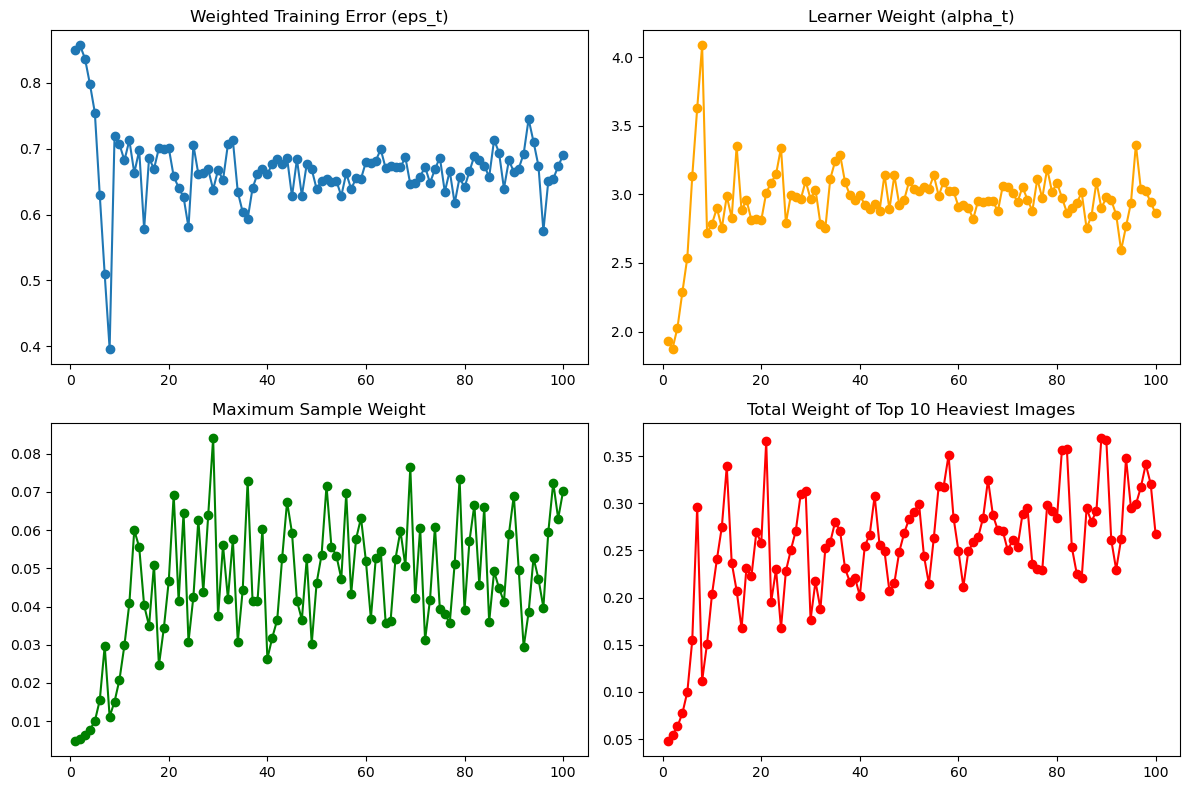

In [12]:
# Q2(b)
data = np.load("olivetti_splits.npz")
X_train, y_train = data["x_train"], data["y_train"]
X_val, y_val = data["x_val"], data["y_val"]
X_test_clean, y_test = data["x_test"], data["y_test"]
X_test_masked = data["x_test_masked"]

print(f"Train size: {X_train.shape}, Val size: {X_val.shape}, Test size: {X_test_clean.shape}")

K = 40
depths = [1, 2, 3, 4]
rounds = [10, 25, 50, 100]

def train_samme(X_tr, y_tr, max_depth, n_rounds):
    N = len(X_tr)
    w = np.ones(N) / N
    models, alphas = [], []
    err_history, alpha_history, max_w_history, top10_w_history = [], [], [], []
    for t in range(n_rounds):
        dt = DecisionTreeClassifier(max_depth=max_depth, random_state=t)
        dt.fit(X_tr, y_tr, sample_weight=w)
        preds = dt.predict(X_tr)
        mistakes = (preds != y_tr)
        err_t = np.sum(w[mistakes])
        if err_t >= (1.0 - 1.0 / K):
            break

        if err_t == 0:
            alpha_t = np.log((1 - 1e-10) / 1e-10) + np.log(K - 1)
        else:
            alpha_t = np.log((1 - err_t) / err_t) + np.log(K - 1)

        w_unnorm = w * np.exp(alpha_t * mistakes)
        w = w_unnorm / np.sum(w_unnorm)
        models.append(dt)
        alphas.append(alpha_t)
        err_history.append(err_t)
        alpha_history.append(alpha_t)
        max_w_history.append(np.max(w))
        top10_w_history.append(np.sum(np.sort(w)[-10:]))

    return models, alphas, w, err_history, alpha_history, max_w_history, top10_w_history

def predict_samme(models, alphas, X_data):
    n_samples = len(X_data)
    scores = np.zeros((n_samples, K))
    for dt, alpha in zip(models, alphas):
        preds = dt.predict(X_data)
        for i in range(n_samples):
            scores[i, preds[i]] += alpha

    final_preds = np.argmax(scores, axis=1)
    confidences = np.max(scores, axis=1) / np.sum(alphas)
    return final_preds, confidences

best_val_acc = -1
best_samme_model = None
for d in depths:
    for r in rounds:
        models, alphas, _, _, _, _, _ = train_samme(X_train, y_train, d, r)
        val_preds, _ = predict_samme(models, alphas, X_val)
        val_acc = np.mean(val_preds == y_val)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_samme_model = (d, r)

print(f"\nModel Selection:")
print(f"Best SAMME parameters (depth, rounds): {best_samme_model} with Val Acc: {best_val_acc:.4f}")
best_d, best_r = best_samme_model
final_models, final_alphas, final_weights, err_hist, alpha_hist, max_w_hist, top10_w_hist = train_samme(
    X_train, y_train, best_d, best_r
)

plt.figure(figsize=(12, 8))
rounds_arr = np.arange(1, len(err_hist) + 1)
plt.subplot(2, 2, 1)
plt.plot(rounds_arr, err_hist, marker='o')
plt.title("Weighted Training Error (eps_t)")
plt.subplot(2, 2, 2)
plt.plot(rounds_arr, alpha_hist, marker='o', color='orange')
plt.title("Learner Weight (alpha_t)")
plt.subplot(2, 2, 3)
plt.plot(rounds_arr, max_w_hist, marker='o', color='green')
plt.title("Maximum Sample Weight")
plt.subplot(2, 2, 4)
plt.plot(rounds_arr, top10_w_hist, marker='o', color='red')
plt.title("Total Weight of Top 10 Heaviest Images")
plt.tight_layout()
plt.show()

In [13]:
# Q2(c)
rounds_c = [25, 50, 100]

for r in rounds_c:
    start_time = time.time()
    bag_models = []
    N = len(x_train)

    for i in range(r):
        boot_idx = rng.choice(N, size=N, replace=True)
        dt = DecisionTreeClassifier(max_depth=8, random_state=i)
        dt.fit(x_train[boot_idx], y_train[boot_idx])
        bag_models.append(dt)

    bag_time = time.time() - start_time

    bag_train_preds = np.array([m.predict(x_train) for m in bag_models])
    bag_train_maj = [
        np.bincount(bag_train_preds[:, i]).argmax()
        for i in range(len(x_train))
    ]
    bag_train_acc = np.mean(bag_train_maj == y_train)

    bag_val_preds = np.array([m.predict(x_val) for m in bag_models])
    bag_val_maj = [
        np.bincount(bag_val_preds[:, i]).argmax()
        for i in range(len(x_val))
    ]
    bag_val_acc = np.mean(bag_val_maj == y_val)

    bag_test_preds = np.array([m.predict(x_test) for m in bag_models])
    bag_test_maj = [
        np.bincount(bag_test_preds[:, i]).argmax()
        for i in range(len(x_test))
    ]
    bag_test_acc = np.mean(bag_test_maj == y_test)

    start_time = time.time()
    b_models, b_alphas, _, _, _, _, _ = train_samme(
        x_train, y_train, best_d, r
    )
    boost_time = time.time() - start_time

    boost_tr_p, _ = predict_samme(b_models, b_alphas, x_train)
    boost_v_p, _ = predict_samme(b_models, b_alphas, x_val)
    boost_te_p, _ = predict_samme(b_models, b_alphas, x_test)

    boost_train_acc = np.mean(boost_tr_p == y_train)
    boost_val_acc = np.mean(boost_v_p == y_val)
    boost_test_acc = np.mean(boost_te_p == y_test)

    print(f"Rounds: {r}")
    print(f"  Bagging  | Train: {bag_train_acc:.3f}, Val: {bag_val_acc:.3f}, Test: {bag_test_acc:.3f} | Time: {bag_time:.3f}s")
    print(f"  Boosting | Train: {boost_train_acc:.3f}, Val: {boost_val_acc:.3f}, Test: {boost_test_acc:.3f} | Time: {boost_time:.3f}s")

heaviest_idx = np.argmax(final_weights)
print(f"\nHeaviest Training Image Index: {heaviest_idx}")
print(f"Final Weight: {final_weights[heaviest_idx]:.4f}")

history = [
    m.predict(x_train[heaviest_idx].reshape(1, -1))[0] == y_train[heaviest_idx]
    for m in final_models[:25]
]
print(f"Prediction History (True/False) first 25 rounds: \n{history}")

Rounds: 25
  Bagging  | Train: 0.842, Val: 0.500, Test: 0.562 | Time: 26.369s
  Boosting | Train: 0.533, Val: 0.237, Test: 0.275 | Time: 17.675s
Rounds: 50
  Bagging  | Train: 0.779, Val: 0.487, Test: 0.562 | Time: 47.738s
  Boosting | Train: 0.958, Val: 0.412, Test: 0.375 | Time: 33.768s
Rounds: 100
  Bagging  | Train: 0.762, Val: 0.537, Test: 0.512 | Time: 96.112s
  Boosting | Train: 0.996, Val: 0.425, Test: 0.375 | Time: 66.584s

Heaviest Training Image Index: 57
Final Weight: 0.0702
Prediction History (True/False) first 25 rounds: 
[False, False, False, False, True, False, False, False, False, False, False, True, False, False, False, False, False, False, False, False, False, True, False, False, False]



Robustness Evaluation:
Bagging (Clean)  - Acc: 0.5125
Bagging (Masked) - Acc: 0.4750, Mean Conf: 0.1625
Boosting (Clean) - Acc: 0.3750, Mean Conf: 0.1177
Boosting (Masked)- Acc: 0.2875, Mean Conf: 0.1231

Divergence on Masked Test Face Index: 6
True Class: 3
Bagging Pred: 12 (Vote fraction: 0.1200)
Boosting Pred: 14 (Confidence: 0.1044)


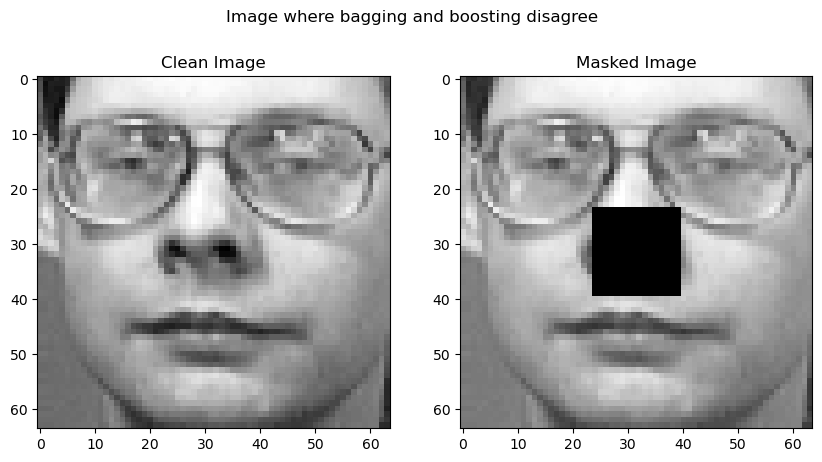

In [14]:
# Q2(d)
bag_mask_preds_raw = np.array([m.predict(X_test_masked) for m in bag_models])
bag_mask_maj = []
bag_mask_conf = []

for i in range(len(X_test_masked)):
    counts = np.bincount(bag_mask_preds_raw[:, i], minlength=K)
    best_class = counts.argmax()
    bag_mask_maj.append(best_class)
    bag_mask_conf.append(counts[best_class] / len(bag_models))

bag_mask_maj = np.array(bag_mask_maj)
boost_clean_preds, boost_clean_conf = predict_samme(
    final_models, final_alphas, X_test_clean
)
boost_mask_preds, boost_mask_conf = predict_samme(
    final_models, final_alphas, X_test_masked
)
print("\nRobustness Evaluation:")
print(f"Bagging (Clean)  - Acc: {bag_test_acc:.4f}")
print(f"Bagging (Masked) - Acc: {np.mean(bag_mask_maj == y_test):.4f}, Mean Conf: {np.mean(bag_mask_conf):.4f}")
print(f"Boosting (Clean) - Acc: {np.mean(boost_clean_preds == y_test):.4f}, Mean Conf: {np.mean(boost_clean_conf):.4f}")
print(f"Boosting (Masked)- Acc: {np.mean(boost_mask_preds == y_test):.4f}, Mean Conf: {np.mean(boost_mask_conf):.4f}")

diverge_idx = np.where(bag_mask_maj != boost_mask_preds)[0]

if len(diverge_idx) > 0:
    idx = diverge_idx[0]

    clean_face = X_test_clean[idx].reshape(64, 64)
    masked_face = X_test_masked[idx].reshape(64, 64)

    print(f"\nDivergence on Masked Test Face Index: {idx}")
    print(f"True Class: {y_test[idx]}")
    print(f"Bagging Pred: {bag_mask_maj[idx]} (Vote fraction: {bag_mask_conf[idx]:.4f})")
    print(f"Boosting Pred: {boost_mask_preds[idx]} (Confidence: {boost_mask_conf[idx]:.4f})")

    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    fig.suptitle("Image where bagging and boosting disagree")

    axes[0].imshow(clean_face, cmap="gray")
    axes[0].set_title("Clean Image")
    axes[1].imshow(masked_face, cmap="gray")
    axes[1].set_title("Masked Image")
    plt.show()
else:
    print("No diverging predictions found between Bagging and Boosting on the masked dataset.")

In [15]:
import time
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier

roll_number = "M26CSE017"
seed = int("".join(ch for ch in roll_number if ch.isdigit()))

data = np.load("olivetti_splits.npz")
x_train, y_train = data["x_train"], data["y_train"]
x_val, y_val = data["x_val"], data["y_val"]
x_test, y_test = data["x_test"], data["y_test"]
x_test_masked = data["x_test_masked"]

FROZEN_DEPTH = None
FROZEN_MIN_LEAF = 1
B_FINAL = 200
BEST_BOOST_DEPTH = 4
BEST_BOOST_ROUNDS = 100

st_clean_acc, st_mask_acc = 0.8750,0.8750
bag_clean_acc, bag_mask_acc = 0.4750, 0.4750
bst_clean_acc, bst_mask_acc = 0.3750, 0.2875

def samme_single_step(X_data, y_data, w, max_depth, K, tree_seed):
    tree = DecisionTreeClassifier(max_depth=max_depth, random_state=tree_seed)
    tree.fit(X_data, y_data, sample_weight=w)
    preds = tree.predict(X_data)
    incorrect = (preds != y_data).astype(float)
    err = float(np.dot(w, incorrect) / np.sum(w))
    max_allowed_err = 1.0 - 1.0 / K

    if err >= max_allowed_err - 1e-12:
        return tree, preds, err, 0.0, w.copy(), False

    err_clipped = np.clip(err, 1e-12, max_allowed_err - 1e-12)
    alpha = float(np.log((1.0 - err_clipped) / err_clipped) + np.log(K - 1.0))
    w_unnorm = w * np.exp(alpha * incorrect)
    w_updated = w_unnorm / np.sum(w_unnorm)
    return tree, preds, err, alpha, w_updated, True

def fit_samme_full(X_tr, y_tr, max_depth, n_rounds, K=40, base_seed=seed):
    rng_boost = np.random.default_rng(base_seed)
    N = len(X_tr)
    w = np.ones(N) / N
    trees, alphas = [], []

    for t in range(n_rounds):
        tree_seed = int(rng_boost.integers(0, 2**31 - 1))
        tree, preds, err, alpha, w_next, valid = samme_single_step(
            X_tr, y_tr, w, max_depth, K, tree_seed
        )

        if not valid:
            if len(trees) == 0:
                trees.append(tree)
                alphas.append(1.0)
            break

        trees.append(tree)
        alphas.append(alpha)
        w = w_next

    return {"trees": trees, "alphas": np.array(alphas)}

def predict_samme(model_dict, X_eval, n_rounds=None, K=40):
    trees = model_dict["trees"][:n_rounds]
    alphas = model_dict["alphas"][:n_rounds]
    scores = np.zeros((len(X_eval), K))
    for tree, alpha in zip(trees, alphas):
        preds = tree.predict(X_eval)
        scores[np.arange(len(X_eval)), preds] += alpha

    q = scores / np.sum(alphas)
    return np.argmax(q, axis=1), float(np.mean(np.max(q, axis=1))), q

R = 30
N_test = len(x_test)
K = 40
E_test = np.eye(K)[y_test]
rng_q3 = np.random.default_rng(seed)
resampled_indices_list = []

for r in range(R):
    r_indices = []
    for person_id in range(K):
        id_mask = np.where(y_train == person_id)[0]
        r_indices.extend(rng_q3.choice(id_mask, size=6, replace=True))
    resampled_indices_list.append(np.array(r_indices))

def compute_bv_metrics(P_array, E_target, y_true):
    P_bar = np.mean(P_array, axis=0)
    bias_sq = float(np.mean(np.sum((P_bar - E_target) ** 2, axis=-1)))
    variance = float(np.mean(np.sum((P_array - P_bar[None, :, :]) ** 2, axis=-1)))
    preds_r = np.argmax(P_array, axis=-1)
    accs_r = np.mean(preds_r == y_true[None, :], axis=1)
    return bias_sq, variance, float(np.mean(accs_r)), float(np.std(accs_r))

P_single_d4 = np.zeros((R, N_test, K))
P_single_d16 = np.zeros((R, N_test, K))
P_single_dNone = np.zeros((R, N_test, K))
P_bag100_d4 = np.zeros((R, N_test, K))
P_bag100_d16 = np.zeros((R, N_test, K))
P_bag100_dNone = np.zeros((R, N_test, K))
P_bag200_dNone = np.zeros((R, N_test, K))
P_boost_sel = np.zeros((R, N_test, K))

print("Running Q3...")
t_start = time.time()

for r in range(R):
    idx_r = resampled_indices_list[r]
    X_r, y_r = x_train[idx_r], y_train[idx_r]
    r_seed = int(rng_q3.integers(0, 2**31 - 1))

    for d_val, P_store in [
        (4, P_single_d4),
        (16, P_single_d16),
        (None, P_single_dNone)
    ]:
        st = DecisionTreeClassifier(
            max_depth=d_val,
            min_samples_leaf=FROZEN_MIN_LEAF,
            random_state=r_seed
        )
        st.fit(X_r, y_r)
        P_store[r] = st.predict_proba(x_test)

    for d_val, B_run in [(4, 100), (16, 100), (None, 200)]:
        rng_b = np.random.default_rng(r_seed)
        votes_100 = np.zeros((N_test, K))
        votes_200 = np.zeros((N_test, K))

        for b in range(B_run):
            boot_idx = rng_b.choice(len(X_r), size=len(X_r), replace=True)
            t_seed = int(rng_b.integers(0, 2**31 - 1))

            tree = DecisionTreeClassifier(
                max_depth=d_val,
                min_samples_leaf=FROZEN_MIN_LEAF,
                random_state=t_seed
            )
            tree.fit(X_r[boot_idx], y_r[boot_idx])
            preds_b = tree.predict(x_test)

            if b < 100:
                votes_100[np.arange(N_test), preds_b] += 1
            votes_200[np.arange(N_test), preds_b] += 1

        if d_val == 4:
            P_bag100_d4[r] = votes_100 / 100
        elif d_val == 16:
            P_bag100_d16[r] = votes_100 / 100
        else:
            P_bag100_dNone[r] = votes_100 / 100
            P_bag200_dNone[r] = votes_200 / 200

    boost_r = fit_samme_full(
        X_r, y_r, BEST_BOOST_DEPTH, BEST_BOOST_ROUNDS, K, r_seed
    )
    _, _, q_r = predict_samme(boost_r, x_test, BEST_BOOST_ROUNDS, K)
    P_boost_sel[r] = q_r

    if (r + 1) % 5 == 0 or r == 0:
        print(f"Completed {r + 1}/{R} ({time.time() - t_start:.1f}s)")

q3a_models = [
    ("Single Tree", P_single_dNone),
    (f"Bagging (B={B_FINAL})", P_bag200_dNone),
    (f"Boosting (T={BEST_BOOST_ROUNDS})", P_boost_sel)
]

rows_q3a = []
bv_lookup = {}

for name, P_mat in q3a_models:
    b2, var, mean_acc, std_acc = compute_bv_metrics(P_mat, E_test, y_test)
    bv_lookup[name] = (b2, var, mean_acc, std_acc)
    rows_q3a.append({
        "Model": name,
        "Bias^2": round(b2, 4),
        "Variance": round(var, 4),
        "Bias^2 + Var": round(b2 + var, 4),
        "Mean Test Acc": round(mean_acc, 4),
        "Std Test Acc": round(std_acc, 4)
    })

df_q3a = pd.DataFrame(rows_q3a)
print("\nQ3(a)")
print(df_q3a.to_string(index=False))

depth_configs = [
    ("Depth 4", P_single_d4, P_bag100_d4),
    ("Depth 16", P_single_d16, P_bag100_d16),
    ("Depth None", P_single_dNone, P_bag100_dNone)
]

rows_q3b = []

for label, P_st, P_bg in depth_configs:
    st_b2, st_var, st_acc, st_std = compute_bv_metrics(P_st, E_test, y_test)
    bg_b2, bg_var, bg_acc, bg_std = compute_bv_metrics(P_bg, E_test, y_test)

    rows_q3b.append({
        "Depth": label,
        "Single Tree Bias^2": round(st_b2, 4),
        "Bagging Bias^2": round(bg_b2, 4),
        "Single Tree Var": round(st_var, 4),
        "Bagging Var": round(bg_var, 4),
        "Var Removed (%)": round(100 * (st_var - bg_var) / st_var, 2) if st_var else 0,
        "Single Tree Acc": round(st_acc, 4),
        "Bagging Acc": round(bg_acc, 4),
        "Acc Gain": round(bg_acc - st_acc, 4)
    })

df_q3b = pd.DataFrame(rows_q3b)
print("\nQ3(b) and Q3(c)")
print(df_q3b.to_string(index=False))

st_b2, st_var, _, _ = bv_lookup["Single Tree"]
bag_b2, bag_var, _, _ = bv_lookup[f"Bagging (B={B_FINAL})"]
bst_b2, bst_var, _, _ = bv_lookup[f"Boosting (T={BEST_BOOST_ROUNDS})"]

df_q3d = pd.DataFrame([
    {
        "Model": "Single Tree",
        "Clean Test Acc": round(st_clean_acc, 4),
        "Masked Test Acc": round(st_mask_acc, 4),
        "Bias^2": round(st_b2, 4),
        "Variance": round(st_var, 4)
    },
    {
        "Model": f"Bagging (B={B_FINAL})",
        "Clean Test Acc": round(bag_clean_acc, 4),
        "Masked Test Acc": round(bag_mask_acc, 4),
        "Bias^2": round(bag_b2, 4),
        "Variance": round(bag_var, 4)
    },
    {
        "Model": f"Boosting (T={BEST_BOOST_ROUNDS})",
        "Clean Test Acc": round(bst_clean_acc, 4),
        "Masked Test Acc": round(bst_mask_acc, 4),
        "Bias^2": round(bst_b2, 4),
        "Variance": round(bst_var, 4)
    }
])

print("\nQ3(d)")
print(df_q3d.to_string(index=False))

Running Q3...
Completed 1/30 (673.8s)
Completed 5/30 (3229.4s)
Completed 10/30 (6415.1s)
Completed 15/30 (9560.0s)
Completed 20/30 (12739.4s)
Completed 25/30 (15914.5s)
Completed 30/30 (19061.8s)

Q3(a)
           Model  Bias^2  Variance  Bias^2 + Var  Mean Test Acc  Std Test Acc
     Single Tree  0.3773    0.6377        1.0150         0.4925        0.0593
 Bagging (B=200)  0.5056    0.0207        0.5263         0.7921        0.0341
Boosting (T=100)  0.8874    0.0162        0.9037         0.3133        0.0871

Q3(b) and Q3(c)
     Depth  Single Tree Bias^2  Bagging Bias^2  Single Tree Var  Bagging Var  Var Removed (%)  Single Tree Acc  Bagging Acc  Acc Gain
   Depth 4              0.8571          0.8916           0.0757       0.0130            82.77           0.0962       0.2650    0.1687
  Depth 16              0.6355          0.6681           0.2303       0.0200            91.33           0.2796       0.6492    0.3696
Depth None              0.3773          0.5075           0.6377   